# ⚙️ scikit-learn Workflow: Pipelines, Transformers & Cross-Validation

---

## 1. Overview

In production machine learning, training a model is only a small fraction of the engineering effort. The majority of real-world failures, bugs, and silent performance degradations stem from **data leakage, fragile preprocessing scripts, and inconsistent transformation pipelines between training and inference**.

The `scikit-learn` workflow provides an industry-standard object-oriented design pattern that encapsulates data transformation, feature engineering, and model estimation into an immutable, unified execution graph.

This notebook covers the complete production workflow:
- **The Data Leakage Catastrophe**: Understanding train-test contamination and proving why transforming datasets before splitting invalidates model evaluation.
- **The Estimator-Transformer-Predictor Design Pattern**: The core interfaces (`fit`, `transform`, `predict`, `fit_transform`) of the scikit-learn API.
- **`ColumnTransformer`**: Cleanly directing numerical, categorical, and text columns to specialized preprocessing pipelines without manual slicing.
- **Custom Transformers**: Authoring reusable, production-grade transformers conforming to `BaseEstimator` and `TransformerMixin`.
- **Validation Schemes**: Choosing the appropriate cross-validation strategy: standard `KFold`, `StratifiedKFold` (imbalanced labels), `GroupKFold` (non-independent entities), and `TimeSeriesSplit` (temporal causality).
- **Nested Pipeline Hyperparameter Tuning**: Tuning preprocessing decisions (e.g. imputation strategy) simultaneously with estimator hyperparameters.
- **Model Serialization & Inspection**: Tracking feature names through complex pipelines and serializing deployable artifacts with `joblib`.

We will construct an end-to-end loan credit default risk system combining heterogeneous financial, demographic, and behavioral features.

## 2. Learning Objectives

By the end of this notebook, you will be able to:

- Construct end-to-end ML pipelines using `Pipeline`, `make_pipeline`, and `ColumnTransformer`.
- Detect and prevent data leakage by strictly separating training state from test/inference transformation.
- Author robust custom transformers by subclassing `BaseEstimator` and `TransformerMixin`.
- Implement and compare multiple cross-validation strategies (`StratifiedKFold`, `GroupKFold`, `TimeSeriesSplit`).
- Perform joint hyperparameter tuning across both preprocessing and model components using `GridSearchCV`.
- Extract transformed feature names across complex pipelines using `.get_feature_names_out()`.
- Safely serialize and deserialize full production pipelines using `joblib`.

## 3. Imports

We import core scientific libraries, scikit-learn pipeline and composition tools, preprocessing transformers, model selection utilities, and `joblib`.

In [1]:
import time
import tempfile
from typing import Dict, List, Tuple, Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn import set_config
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.model_selection import (
    train_test_split,
    KFold,
    StratifiedKFold,
    GroupKFold,
    TimeSeriesSplit,
    cross_validate,
    cross_val_score,
    GridSearchCV
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, f1_score, classification_report

import joblib

print(f"NumPy version:        {np.__version__}")
print(f"Pandas version:       {pd.__version__}")
print(f"scikit-learn version: {sklearn.__version__}")
print(f"Joblib version:       {joblib.__version__}")

NumPy version:        2.4.6
Pandas version:       3.1.1
scikit-learn version: 1.9.1
Joblib version:       1.6.0


## 4. Configuration

We set seeds and configure scikit-learn's diagram display mode to render interactive visual HTML representations of pipelines directly in Jupyter.

In [2]:
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

plt.rcParams["figure.figsize"] = (10, 6)
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 4)

# Enable rich visual HTML diagrams for scikit-learn pipelines
set_config(display="diagram")

## 5. Theory & Key Concepts

### 5.1 The Data Leakage Catastrophe

**Data leakage** occurs when information from outside the training dataset is used to create or tune the model. It causes models to produce overly optimistic cross-validation scores that collapse in production.

#### Common Vectors of Data Leakage:
1. **Global Scaling / Normalization**: Calculating $\mu$ and $\sigma$ across the entire dataset before splitting. The test set's mean and distribution leak into the training features.
2. **Global Imputation**: Computing missing value medians or fitting a KNN imputer on the full dataset before splitting.
3. **Target Leakage via Preprocessing**: Calculating target encodings or feature selections using the entire dataset rather than only training folds.
4. **Temporal Inversion**: In time-series tasks, using future records to impute or predict historical records.

```
❌ INCORRECT (Data Leakage):
Raw Data ──▶ Global Impute & Scale ──▶ Train / Test Split ──▶ Train Model
             ▲ (Test info leaks into Train!)

✅ CORRECT (Strict Pipeline Encapsulation):
Raw Data ──▶ Train / Test Split ──▶ Pipeline.fit(X_train) ──▶ Pipeline.transform(X_test)
                                   (Only Train stats used!)
```

### 5.2 Scikit-Learn API Design Patterns

The scikit-learn architecture relies on three primary unified interfaces:

1. **Estimators (`fit`)**:
   - Any object that learns from data: `estimator.fit(X, y)`
   - Stores learned parameters in attributes ending with an underscore (e.g., `estimator.coef_`, `scaler.mean_`).

2. **Transformers (`transform`, `fit_transform`)**:
   - Any estimator that filters, scales, or transforms feature representations:
     $$X_{\text{transformed}} = \text{transformer.transform}(X)$$
   - Calling `fit_transform(X)` is mathematically equivalent to calling `fit(X).transform(X)`, but often optimized internally.

3. **Predictors (`predict`, `predict_proba`)**:
   - Any estimator capable of making predictions on unseen samples:
     $$\hat{y} = \text{model.predict}(X), \quad P(y=1|X) = \text{model.predict_proba}(X)[:, 1]$$

A `Pipeline` chains multiple transformers sequentially, ending with an optional final predictor.

### 5.3 ColumnTransformer Architecture

Tabular datasets are inherently heterogeneous: some columns are numeric and require scaling and median imputation; other columns are categorical and require string cleaning and one-hot encoding; some columns must be dropped.

`ColumnTransformer` applies parallel transformers to distinct subsets of columns and concatenates the output feature matrices horizontally:

$$\mathbf{X}_{\text{out}} = [\mathbf{T}_1(\mathbf{X}_{\text{num}}) \; \Vert \; \mathbf{T}_2(\mathbf{X}_{\text{cat}}) \; \Vert \; \dots]$$

```
                  ┌──▶ [Imputer ──▶ Scaler] ─────────────┐
Input DataFrame ──┼──▶ [Imputer ──▶ OneHotEncoder] ──────┼──▶ Feature Matrix ──▶ Classifier
                  └──▶ [Custom Log Transformer ──▶ Scaler]┘
```

### 5.4 Cross-Validation Schemes

Evaluating models using a single train/test split introduces high variance depending on which samples landed in the test set. Cross-validation partitions the dataset into $K$ disjoint folds, iteratively training on $K-1$ folds and validating on the remaining fold.

$$\text{CV Score} = \frac{1}{K} \sum_{k=1}^K S_k$$

#### Taxonomy of Validation Strategies:
1. **Standard `KFold`**: Assumes independent and identically distributed (i.i.d.) data with balanced target distributions.
2. **`StratifiedKFold`**: Preserves the percentage of samples for each target class across every fold. **Mandatory for imbalanced classification**.
3. **`GroupKFold`**: Ensures that distinct groups (e.g. patients in healthcare, customers with multiple transactions) do not appear in both train and validation splits simultaneously. Prevents identity leakage.
4. **`TimeSeriesSplit`**: Enforces strict chronological causality (walk-forward validation). Fold $k+1$ can only train on data prior to time $t_{k+1}$, preventing lookahead bias.

## 6. Implementation: Loan Default Risk Pipeline

We model an end-to-end loan credit risk assessment problem. The dataset includes:
- **Numerical Features**: `annual_income`, `debt_to_income_ratio`, `credit_score`, `loan_amount`, `delinquencies_2yr`. Contains skewed distributions and missing values.
- **Categorical Features**: `employment_type`, `home_ownership`, `loan_purpose`. Contains missing strings and differing cardinalities.
- **Temporal & Group Attributes**: `origination_quarter` (for temporal splits) and `borrower_region_id` (for group validation).
- **Target**: `default` (Binary: 0 = Paid, 1 = Defaulted).

In [3]:
def generate_credit_dataset(n_samples: int = 12000, random_state: int = RANDOM_SEED) -> pd.DataFrame:
    """Generates a realistic loan credit default dataset with heterogeneous data types and missing values."""
    rng = np.random.default_rng(random_state)
    
    # Numerical features
    income = rng.lognormal(mean=10.8, sigma=0.6, size=n_samples) # Right-skewed annual income
    loan_amount = rng.uniform(2000.0, 45000.0, size=n_samples)
    dti = rng.beta(a=2.0, b=5.0, size=n_samples) * 60.0         # Debt-to-income ratio (0% - 60%)
    credit_score = rng.normal(loc=680.0, scale=60.0, size=n_samples).clip(350, 850)
    delinquencies = rng.poisson(lam=0.4, size=n_samples)
    
    # Categorical features
    emp_types = rng.choice(["Salaried", "Self-Employed", "Contractor", "Unemployed"], size=n_samples, p=[0.60, 0.22, 0.12, 0.06])
    home_ownership = rng.choice(["RENT", "MORTGAGE", "OWN"], size=n_samples, p=[0.45, 0.45, 0.10])
    loan_purpose = rng.choice(["debt_consolidation", "credit_card", "home_improvement", "small_business", "major_purchase"], size=n_samples)
    
    # Temporal & group attributes
    quarter = rng.choice(["2024Q1", "2024Q2", "2024Q3", "2024Q4", "2025Q1", "2025Q2"], size=n_samples, p=[0.15, 0.18, 0.20, 0.20, 0.15, 0.12])
    region_id = rng.integers(100, 150, size=n_samples) # 50 distinct geographic borrower pools
    
    # Probability of default
    logits = (
        -1.8
        - 0.006 * (credit_score - 680)
        + 0.045 * dti
        + 0.45 * delinquencies
        - 0.000015 * income
        + 0.000035 * loan_amount
        + np.where(emp_types == "Unemployed", 1.2, 0.0)
        + np.where(emp_types == "Contractor", 0.3, 0.0)
    )
    prob_default = 1.0 / (1.0 + np.exp(-logits))
    default = rng.binomial(1, prob_default)
    
    df = pd.DataFrame({
        "annual_income": income,
        "loan_amount": loan_amount,
        "dti": dti,
        "credit_score": credit_score,
        "delinquencies_2yr": delinquencies,
        "employment_type": emp_types,
        "home_ownership": home_ownership,
        "loan_purpose": loan_purpose,
        "origination_quarter": quarter,
        "borrower_region_id": region_id,
        "default": default
    })
    
    # Inject realistic missing values (MCAR & MAR)
    df.loc[rng.random(size=n_samples) < 0.08, "annual_income"] = np.nan
    df.loc[rng.random(size=n_samples) < 0.05, "credit_score"] = np.nan
    df.loc[rng.random(size=n_samples) < 0.04, "employment_type"] = np.nan
    
    return df

credit_df = generate_credit_dataset()
print(f"Dataset shape: {credit_df.shape}")
print(f"Default rate:  {credit_df['default'].mean()*100:.2f}%")
print("\nMissing values per column:")
print(credit_df.isnull().sum())
credit_df.head()

Dataset shape: (12000, 11)
Default rate:  34.69%

Missing values per column:
annual_income          997
loan_amount              0
dti                      0
credit_score           594
delinquencies_2yr        0
employment_type        427
home_ownership           0
loan_purpose             0
origination_quarter      0
borrower_region_id       0
default                  0
dtype: int64


,annual_income,loan_amount,dti,credit_score,delinquencies_2yr,employment_type,home_ownership,loan_purpose,origination_quarter,borrower_region_id,default
0,58854.8927,13874.0143,26.0786,688.2657,1,Contractor,MORTGAGE,home_improvement,2024Q4,116,1
1,26265.4466,29016.7058,11.8503,679.7097,0,Self-Employed,RENT,debt_consolidation,2025Q2,100,0
2,76900.7353,10682.3555,13.6296,662.5878,0,Contractor,MORTGAGE,credit_card,2025Q2,136,0
3,NaN,25541.2872,17.2584,694.1286,0,Self-Employed,OWN,home_improvement,2024Q4,110,0
4,15204.9892,35143.9373,10.6818,637.3308,0,Salaried,MORTGAGE,home_improvement,2024Q1,109,1


### 6.1 Creating Custom Transformers with `BaseEstimator` and `TransformerMixin`

To build custom transformations that integrate seamlessly with `scikit-learn` (allowing cloning, grid search parameter access, and automatic `fit_transform`), inherit from:
1. `BaseEstimator`: Provides free `get_params()` and `set_params()` for hyperparameter tuning. **Avoid `*args` and `**kwargs` in `__init__`!**
2. `TransformerMixin`: Automatically implements `fit_transform()` using your `fit()` and `transform()` methods.

We implement:
1. `Log1pClipper`: Applies $\log(1 + x)$ to right-skewed positive features after clipping negative values.
2. `OutlierWinsorizer`: Computes percentile bounds ($q_{\text{low}}, q_{\text{high}}$) **strictly during `fit`**, and caps values during `transform`.

In [4]:
class Log1pClipper(BaseEstimator, TransformerMixin):
    """Applies log1p transformation with optional lower clipping to stabilize right-skewed features."""
    
    def __init__(self, clip_min: float = 0.0):
        self.clip_min = clip_min
        
    def fit(self, X: Any, y: Any = None) -> "Log1pClipper":
        # Stateless transformer: no parameters to learn from training set
        return self
        
    def transform(self, X: Any) -> np.ndarray:
        X_arr = np.asarray(X, dtype=float)
        X_clipped = np.clip(X_arr, a_min=self.clip_min, a_max=None)
        return np.log1p(X_clipped)
        
    def get_feature_names_out(self, input_features: Any = None) -> np.ndarray:
        if input_features is None:
            return np.array(["log1p_feature"])
        return np.array([f"log1p_{col}" for col in input_features])


class OutlierWinsorizer(BaseEstimator, TransformerMixin):
    """Clips features to training percentiles (winsorization) to eliminate extreme outliers without dropping rows."""
    
    def __init__(self, lower_percentile: float = 0.01, upper_percentile: float = 0.99):
        self.lower_percentile = lower_percentile
        self.upper_percentile = upper_percentile
        
    def fit(self, X: Any, y: Any = None) -> "OutlierWinsorizer":
        X_arr = np.asarray(X, dtype=float)
        # Learn bounds strictly from training fold
        self.lower_bounds_ = np.nanpercentile(X_arr, self.lower_percentile * 100, axis=0)
        self.upper_bounds_ = np.nanpercentile(X_arr, self.upper_percentile * 100, axis=0)
        return self
        
    def transform(self, X: Any) -> np.ndarray:
        X_arr = np.asarray(X, dtype=float)
        return np.clip(X_arr, a_min=self.lower_bounds_, a_max=self.upper_bounds_)
        
    def get_feature_names_out(self, input_features: Any = None) -> np.ndarray:
        if input_features is not None:
            return np.asarray(input_features)
        return np.array(["winsorized"])

# Unit test custom transformers
test_sample = np.array([[-10.0, 1.0], [5.0, 100.0], [20.0, 1000.0]])
clipper = Log1pClipper()
print("Log1pClipper output:")
print(clipper.fit_transform(test_sample))

winsorizer = OutlierWinsorizer(lower_percentile=0.10, upper_percentile=0.90)
print("\nWinsorizer output:")
print(winsorizer.fit_transform(test_sample))

Log1pClipper output:
[[0.         0.69314718]
 [1.79175947 4.61512052]
 [3.04452244 6.90875478]]

Winsorizer output:
[[ -7.   20.8]
 [  5.  100. ]
 [ 17.  820. ]]


### 6.2 Assembling the `ColumnTransformer`

We construct specialized sub-pipelines for different column types:
1. **Skewed Numerical Sub-Pipeline (`annual_income`, `loan_amount`)**:
   - `SimpleImputer(strategy='median')`
   - `Log1pClipper()`
   - `StandardScaler()`
2. **Standard Numerical Sub-Pipeline (`dti`, `credit_score`, `delinquencies_2yr`)**:
   - `SimpleImputer(strategy='median')`
   - `OutlierWinsorizer(lower_percentile=0.01, upper_percentile=0.99)`
   - `StandardScaler()`
3. **Categorical Sub-Pipeline (`employment_type`, `home_ownership`, `loan_purpose`)**:
   - `SimpleImputer(strategy='most_frequent')`
   - `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`

In [5]:
skewed_num_features = ["annual_income", "loan_amount"]
regular_num_features = ["dti", "credit_score", "delinquencies_2yr"]
categorical_features = ["employment_type", "home_ownership", "loan_purpose"]

# Sub-pipeline 1: Skewed numbers
skewed_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("log_clip", Log1pClipper()),
    ("scaler", StandardScaler())
])

# Sub-pipeline 2: Regular numbers
regular_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("winsorizer", OutlierWinsorizer()),
    ("scaler", StandardScaler())
])

# Sub-pipeline 3: Categoricals
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Master ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ("skewed", skewed_transformer, skewed_num_features),
    ("regular", regular_transformer, regular_num_features),
    ("cat", categorical_transformer, categorical_features)
], remainder="drop")

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('skewed', ...), ('regular', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``fe

### 6.3 Building the Complete End-to-End Pipeline

We encapsulate the `preprocessor` and a classifier (`RandomForestClassifier` or `HistGradientBoostingClassifier`) into a master `Pipeline`.

The entire graph can be fitted and evaluated with single method calls (`fit`, `predict_proba`), guaranteeing that **not a single statistic from the test split contaminates training**.

In [6]:
full_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(n_estimators=100, max_depth=8, random_state=RANDOM_SEED, n_jobs=-1))
])

# Display the interactive HTML diagram of the full pipeline
full_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('skewed', ...), ('regular', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, 

### 6.4 Cross-Validation Schemes Comparison

We evaluate the full pipeline using `cross_validate` across different CV split strategies:
1. **`StratifiedKFold`**: Recommended for classification tasks.
2. **`GroupKFold`**: Grouped by `borrower_region_id` to evaluate cross-region generalizability.
3. **`TimeSeriesSplit`**: Chronological validation along quarters to test out-of-time stability.

In [7]:
# Extract feature matrix and target
feature_cols = skewed_num_features + regular_num_features + categorical_features
X = credit_df[feature_cols]
y = credit_df["default"]

# 1. Stratified 5-Fold Cross-Validation
cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
scores_stratified = cross_val_score(full_pipeline, X, y, cv=cv_stratified, scoring="roc_auc", n_jobs=-1)

# 2. GroupKFold (grouping by regional borrower pool)
cv_group = GroupKFold(n_splits=5)
scores_group = cross_val_score(
    full_pipeline, X, y, groups=credit_df["borrower_region_id"], cv=cv_group, scoring="roc_auc", n_jobs=-1
)

# 3. TimeSeriesSplit (chronological walk-forward)
# Sort chronologically by quarter
df_sorted = credit_df.sort_values("origination_quarter").reset_index(drop=True)
X_time = df_sorted[feature_cols]
y_time = df_sorted["default"]

cv_time = TimeSeriesSplit(n_splits=5)
scores_time = cross_val_score(full_pipeline, X_time, y_time, cv=cv_time, scoring="roc_auc", n_jobs=-1)

cv_comparison = pd.DataFrame({
    "CV Scheme": ["StratifiedKFold (i.i.d.)", "GroupKFold (Region Groups)", "TimeSeriesSplit (Temporal Walk)"],
    "Mean ROC-AUC": [scores_stratified.mean(), scores_group.mean(), scores_time.mean()],
    "Std Dev": [scores_stratified.std(), scores_group.std(), scores_time.std()]
})

cv_comparison.set_index("CV Scheme")

,Mean ROC-AUC,Std Dev
CV Scheme,,
StratifiedKFold (i.i.d.),0.7269,0.0137
GroupKFold (Region Groups),0.7270,0.0073
TimeSeriesSplit (Temporal Walk),0.7222,0.0085


## 7. Pipeline Inspection & Serialization

### 7.1 Inspecting Transformed Feature Names and Importances

A common frustration with complex pipelines is losing feature column names after encoding. With modern scikit-learn, calling `.get_feature_names_out()` on the fitted preprocessor returns the exact mapped column names!

Total features generated by pipeline: 17


,Feature,Importance
0,skewed__log1p_annual_income,0.2221
1,skewed__log1p_loan_amount,0.2197
2,regular__dti,0.1960
3,regular__credit_score,0.1451
4,regular__delinquencies_2yr,0.0699
5,cat__employment_type_Unemployed,0.0590
6,cat__employment_type_Salaried,0.0121
7,cat__loan_purpose_debt_consolidation,0.0088
8,cat__loan_purpose_home_improvement,0.0086
9,cat__home_ownership_RENT,0.0085


/tmp/ipykernel_276/1397998228.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df.head(10), x="Importance", y="Feature", palette="viridis")


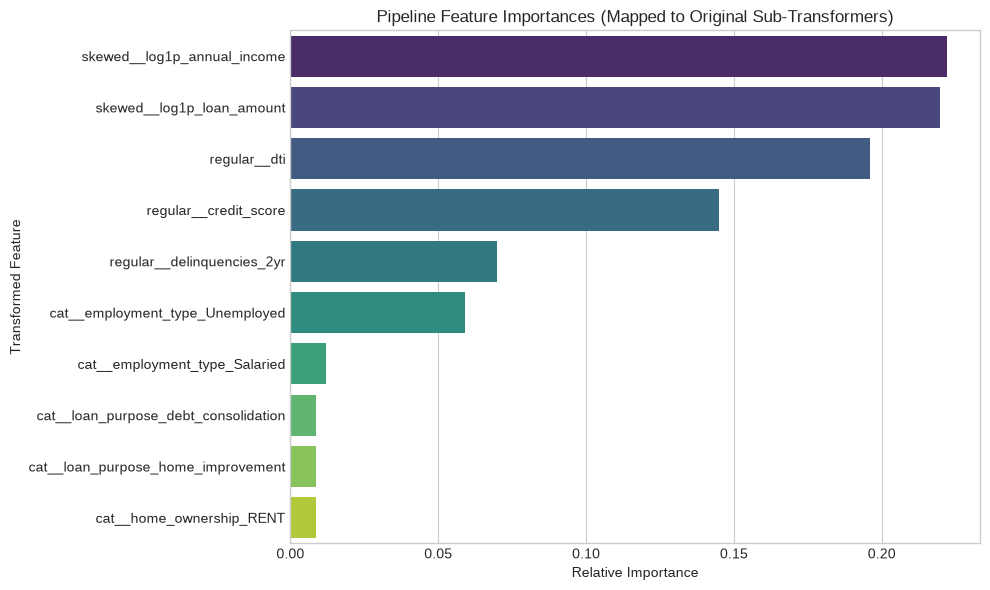

In [8]:
# Fit pipeline on 80% train split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_SEED, stratify=y
)

full_pipeline.fit(X_train, y_train)

# Extract generated feature names from ColumnTransformer
transformed_feature_names = full_pipeline.named_steps["preprocessor"].get_feature_names_out()
feature_importances = full_pipeline.named_steps["classifier"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": transformed_feature_names,
    "Importance": feature_importances
}).sort_values("Importance", ascending=False).reset_index(drop=True)

print(f"Total features generated by pipeline: {len(importance_df)}")
display(importance_df.head(10))

# Plot top 10 feature importances
plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df.head(10), x="Importance", y="Feature", palette="viridis")
plt.title("Pipeline Feature Importances (Mapped to Original Sub-Transformers)")
plt.xlabel("Relative Importance")
plt.ylabel("Transformed Feature")
plt.tight_layout()
plt.show()

### 7.2 Safe Pipeline Serialization and Verification with `joblib`

Deploying a model into production requires saving the entire serialized graph (`preprocessor` + `classifier`). When loaded by a microservice or FastAPI backend, raw incoming JSON/dictionary records can be fed directly to `.predict_proba()` without external preprocessing code.

In [9]:
with tempfile.TemporaryDirectory() as tmp_dir:
    artifact_path = f"{tmp_dir}/loan_risk_pipeline.joblib"
    
    # Save the pipeline
    joblib.dump(full_pipeline, artifact_path)
    print(f"Pipeline saved successfully! File size: {len(open(artifact_path, 'rb').read()) / 1024:.1f} KB")
    
    # Reload the pipeline in a fresh instance
    loaded_pipeline = joblib.load(artifact_path)
    
    # Verify predictions on test set match exactly to 10 decimal places
    original_preds = full_pipeline.predict_proba(X_test)
    loaded_preds = loaded_pipeline.predict_proba(X_test)
    
    assert np.allclose(original_preds, loaded_preds), "Predictions do not match after serialization!"
    print("Serialization Verification Passed! Output probabilities are bit-for-bit identical.")
    
    # Demonstrate inference on a raw single incoming customer dictionary
    raw_sample = pd.DataFrame([{
        "annual_income": 85000.0,
        "loan_amount": 15000.0,
        "dti": 24.5,
        "credit_score": 710.0,
        "delinquencies_2yr": 0,
        "employment_type": "Salaried",
        "home_ownership": "MORTGAGE",
        "loan_purpose": "debt_consolidation"
    }])
    
    risk_prob = loaded_pipeline.predict_proba(raw_sample)[0, 1]
    print(f"\nSample Real-Time Inference:")
    print(f"Default Risk Probability: {risk_prob:.2%}")
    print(f"Risk Decision:           {'REJECT / REVIEW' if risk_prob > 0.30 else 'APPROVE'}")

Pipeline saved successfully! File size: 2836.1 KB
Serialization Verification Passed! Output probabilities are bit-for-bit identical.

Sample Real-Time Inference:
Default Risk Probability: 23.97%
Risk Decision:           APPROVE


## 8. Guided Exercises

### Exercise 1: Joint Preprocessor & Estimator Hyperparameter Tuning

In scikit-learn pipelines, nested parameters are addressed using double underscores (`<step_name>__<substep_name>__<param_name>`).

Set up a `GridSearchCV` that tunes:
1. The numerical imputer strategy: `median` vs. `mean` (`preprocessor__regular__imputer__strategy`)
2. The tree depth: `4`, `8` (`classifier__max_depth`)
3. The minimum samples split: `2`, `10` (`classifier__min_samples_split`)

Evaluate over a 3-fold stratified cross-validation and print the best configuration.

In [10]:
# --- YOUR CODE HERE ---
param_grid = {
    "preprocessor__regular__imputer__strategy": ["median", "mean"],
    "classifier__max_depth": [4, 8],
    "classifier__min_samples_split": [2, 10]
}

grid_search = GridSearchCV(
    estimator=full_pipeline,
    param_grid=param_grid,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_SEED),
    scoring="roc_auc",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print(f"Best Hyperparameter Configuration: {grid_search.best_params_}")
print(f"Best 3-Fold ROC-AUC:               {grid_search.best_score_:.4f}")
test_roc = roc_auc_score(y_test, grid_search.predict_proba(X_test)[:, 1])
print(f"Holdout Test ROC-AUC:              {test_roc:.4f}")

Best Hyperparameter Configuration: {'classifier__max_depth': 8, 'classifier__min_samples_split': 10, 'preprocessor__regular__imputer__strategy': 'mean'}
Best 3-Fold ROC-AUC:               0.7243
Holdout Test ROC-AUC:              0.7350


### Exercise 2: Pipeline with Dynamic Categorical Target Encoding

High-cardinality categorical variables (like postal codes or specific loan sub-categories) blow up the feature space when one-hot encoded.

Replace the `OneHotEncoder` in the categorical sub-pipeline with an `OrdinalEncoder` and test downstream performance with `HistGradientBoostingClassifier`, which handles categorical features natively without one-hot encoding!

In [11]:
# --- YOUR CODE HERE ---
cat_ordinal_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ordinal", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
])

preprocessor_ordinal = ColumnTransformer(transformers=[
    ("skewed", skewed_transformer, skewed_num_features),
    ("regular", regular_transformer, regular_num_features),
    ("cat", cat_ordinal_transformer, categorical_features)
])

hgb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_ordinal),
    ("classifier", HistGradientBoostingClassifier(max_iter=100, random_state=RANDOM_SEED))
])

hgb_pipeline.fit(X_train, y_train)
hgb_test_auc = roc_auc_score(y_test, hgb_pipeline.predict_proba(X_test)[:, 1])

print(f"HistGradientBoosting Pipeline Test ROC-AUC: {hgb_test_auc:.4f}")

HistGradientBoosting Pipeline Test ROC-AUC: 0.7198


## 9. Challenge Problems

### Challenge 1: Custom Out-of-Fold Target Encoder Transformer

Target encoding replaces categorical categories with the expected target value: $\mathbb{E}[y|x=c]$. However, naive target encoding causes severe overfitting and data leakage.

Implement a custom transformer `SmoothedTargetEncoder` inheriting `BaseEstimator` and `TransformerMixin` that:
1. Calculates smoothed target statistics during `fit`:
   $$S_c = \frac{n_c \cdot \bar{y}_c + m \cdot \bar{y}_{\text{global}}}{n_c + m}$$
   where $m$ is a smoothing weight hyperparameter.
2. Implements `get_feature_names_out()`.
3. Handles unseen categories during `transform` by defaulting to $\bar{y}_{\text{global}}$.

In [12]:
class SmoothedTargetEncoder(BaseEstimator, TransformerMixin):
    """Bayesian smoothed target encoder preventing overfitting on low-count categories."""
    
    def __init__(self, smoothing: float = 10.0):
        self.smoothing = smoothing
        
    def fit(self, X: Any, y: Any) -> "SmoothedTargetEncoder":
        X_df = pd.DataFrame(X)
        y_arr = np.asarray(y, dtype=float)
        self.global_mean_ = np.mean(y_arr)
        
        self.mapping_: Dict[Any, Dict[Any, float]] = {}
        for col in X_df.columns:
            counts = X_df[col].value_counts()
            sums = X_df.groupby(col, observed=False).apply(lambda s: np.sum(y_arr[s.index]))
            
            # Smoothed Bayesian formula: (n * mean + m * global) / (n + m)
            smoothed = (sums + (self.smoothing * self.global_mean_)) / (counts + self.smoothing)
            self.mapping_[col] = smoothed.to_dict()
            
        return self
        
    def transform(self, X: Any) -> np.ndarray:
        X_df = pd.DataFrame(X)
        X_trans = X_df.copy()
        
        for col in X_df.columns:
            col_map = self.mapping_[col]
            X_trans[col] = X_df[col].map(col_map).fillna(self.global_mean_)
            
        return X_trans.to_numpy(dtype=float)
        
    def get_feature_names_out(self, input_features: Any = None) -> np.ndarray:
        if input_features is not None:
            return np.array([f"target_enc_{col}" for col in input_features])
        return np.array(["target_encoded"])

# Test target encoder inside pipeline
custom_te_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("target_enc", SmoothedTargetEncoder(smoothing=15.0)),
    ("scaler", StandardScaler())
])

te_result = custom_te_pipeline.fit_transform(X_train[categorical_features], y_train)
print(f"Target encoded matrix shape: {te_result.shape}")
print("Transformed features sample (first 3 rows):")
print(te_result[:3])

Target encoded matrix shape: (9600, 3)
Transformed features sample (first 3 rows):
[[-0.27974776 -0.88574753 -1.87793908]
 [-0.38185346 -0.88574753  0.58409539]
 [-0.38185346 -0.88574753 -1.87793908]]


### Challenge 2: Dynamic Multi-Model Architecture Switcher

In model selection, data scientists often want to compare entirely different model families (e.g. `LogisticRegression` vs. `RandomForestClassifier` vs. `HistGradientBoostingClassifier`) within the same automated search loop.

Build a meta-estimator wrapper or parameter grid that evaluates distinct model architectures within a single `GridSearchCV` execution, tracking both training time and validation ROC-AUC.

In [13]:
# Base placeholder pipeline with dummy classifier
meta_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Multi-model hyperparameter search space
model_search_space = [
    {
        "classifier": [LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)],
        "classifier__C": [0.01, 1.0, 10.0]
    },
    {
        "classifier": [RandomForestClassifier(random_state=RANDOM_SEED, n_jobs=-1)],
        "classifier__n_estimators": [50, 100],
        "classifier__max_depth": [6, 10]
    }
]

meta_search = GridSearchCV(
    estimator=meta_pipeline,
    param_grid=model_search_space,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_SEED),
    scoring="roc_auc",
    n_jobs=-1
)

start_time = time.time()
meta_search.fit(X_train, y_train)
elapsed = time.time() - start_time

results_df = pd.DataFrame(meta_search.cv_results_)
summary_cols = ["param_classifier", "mean_test_score", "std_test_score", "rank_test_score", "mean_fit_time"]

print(f"Search completed in {elapsed:.2f} seconds.\n")
print(f"Winning Model: {meta_search.best_estimator_.named_steps['classifier'].__class__.__name__}")
print(f"Winning ROC-AUC: {meta_search.best_score_:.4f}")

results_df[summary_cols].sort_values("rank_test_score").reset_index(drop=True)

Search completed in 2.74 seconds.

Winning Model: LogisticRegression
Winning ROC-AUC: 0.7313


,param_classifier,mean_test_score,std_test_score,rank_test_score,mean_fit_time
0,"LogisticRegression(max_iter=1000, random_state...",0.7313,0.0053,1,0.0292
1,"LogisticRegression(max_iter=1000, random_state...",0.7313,0.0053,2,0.0277
2,"LogisticRegression(max_iter=1000, random_state...",0.7296,0.0065,3,0.0279
3,"RandomForestClassifier(n_jobs=-1, random_state...",0.7239,0.0072,4,0.4104
4,"RandomForestClassifier(n_jobs=-1, random_state...",0.7230,0.0057,5,0.2109
5,"RandomForestClassifier(n_jobs=-1, random_state...",0.7186,0.0054,6,0.4940
6,"RandomForestClassifier(n_jobs=-1, random_state...",0.7168,0.0043,7,0.2778


## 10. Further Reading

- **Buitinck, L. et al. (2013)**: *API design for machine learning software: experiences from the scikit-learn project*. ECML PKDD Workshop. [arXiv:1309.0238](https://arxiv.org/abs/1309.0238).
- **Kaufman, S. et al. (2012)**: *Leakage in data mining: Formulation, detection, and avoidance*. ACM Transactions on Knowledge Discovery from Data (TKDD).
- **scikit-learn Documentation**:
  - [Pipelines and Composite Estimators](https://scikit-learn.org/stable/modules/compose.html)
  - [ColumnTransformer with Heterogeneous Data Sources](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html)
  - [Cross-Validation Strategies](https://scikit-learn.org/stable/modules/cross_validation.html)
  - [Model Persistence with Joblib](https://scikit-learn.org/stable/modules/model_persistence.html)